In [2]:
from pathlib import Path
import csv

pasta_atual = Path.cwd()
raiz = pasta_atual.parent if pasta_atual.name == "notebooks" else pasta_atual

pasta_processados = raiz / "data" / "processed"

def carregar_csv(nome):
    caminho = pasta_processados / nome

    with caminho.open("r", encoding="utf-8-sig", newline="") as arquivo:
        return list(csv.DictReader(arquivo, delimiter=";"))

registros_pdf = carregar_csv("textos_pdfs.csv")
registros_html = carregar_csv("textos_html.csv")

print("Raiz utilizada:", raiz)
print("Registros PDF:", len(registros_pdf))
print("Registros HTML:", len(registros_html))
print("Arquivos PDF distintos:", len({r["arquivo"] for r in registros_pdf}))
print("Arquivos HTML distintos:", len({r["arquivo"] for r in registros_html}))

Raiz utilizada: /Users/hugofilho/Documents/projeto-pln
Registros PDF: 116
Registros HTML: 14
Arquivos PDF distintos: 4
Arquivos HTML distintos: 14


In [3]:
from collections import defaultdict

resumo_fontes = defaultdict(
    lambda: {"registros": 0, "caracteres": 0, "sem_texto": 0}
)

for registro in registros_pdf + registros_html:
    arquivo = registro["arquivo"]
    texto = registro["texto"]

    resumo_fontes[arquivo]["registros"] += 1
    resumo_fontes[arquivo]["caracteres"] += len(texto.strip())
    resumo_fontes[arquivo]["sem_texto"] += int(not texto.strip())

for arquivo, resumo in sorted(resumo_fontes.items()):
    print(
        f"{arquivo}\n"
        f"  Registros: {resumo['registros']} | "
        f"Caracteres: {resumo['caracteres']} | "
        f"Sem texto: {resumo['sem_texto']}\n"
    )

05.html
  Registros: 1 | Caracteres: 5850 | Sem texto: 0

06.html
  Registros: 1 | Caracteres: 5503 | Sem texto: 0

07.html
  Registros: 1 | Caracteres: 2468 | Sem texto: 0

08.html
  Registros: 1 | Caracteres: 3050 | Sem texto: 0

09.html
  Registros: 1 | Caracteres: 1427 | Sem texto: 0

10.html
  Registros: 1 | Caracteres: 1093 | Sem texto: 0

11.html
  Registros: 1 | Caracteres: 1292 | Sem texto: 0

12.html
  Registros: 1 | Caracteres: 8758 | Sem texto: 0

13.html
  Registros: 1 | Caracteres: 2601 | Sem texto: 0

14.html
  Registros: 1 | Caracteres: 5000 | Sem texto: 0

15.html
  Registros: 1 | Caracteres: 9704 | Sem texto: 0

16.html
  Registros: 1 | Caracteres: 2342 | Sem texto: 0

17.html
  Registros: 1 | Caracteres: 1930 | Sem texto: 0

18.html
  Registros: 1 | Caracteres: 704 | Sem texto: 0

Calendario_Academico_2026_2_Ibmec_SP_v5_08310586a3.pdf
  Registros: 6 | Caracteres: 3325 | Sem texto: 0

GradManualAlunoIbmec.pdf
  Registros: 49 | Caracteres: 77971 | Sem texto: 1

GuiaCal

In [4]:
assert len(resumo_fontes) == 18, "Esperávamos 18 fontes."

revisao_fontes = {
    arquivo: {
        "decisao": "pendente",
        "observacao": "",
    }
    for arquivo in resumo_fontes
}

observacoes_iniciais = {
    "06.html": "Conferir atualidade das instruções de acesso e senha.",
    "12.html": "Distinguir serviços por público e unidade.",
    "14.html": "Separar orientações gerais dos prazos encerrados de 2026.1.",
    "15.html": "Distinguir divulgação do curso de regras acadêmicas.",
    "16.html": "Avaliar como índice para localizar documentos.",
}

for arquivo, observacao in observacoes_iniciais.items():
    revisao_fontes[arquivo]["observacao"] = observacao

print("Fontes registradas para revisão:", len(revisao_fontes))

for arquivo, revisao in sorted(revisao_fontes.items()):
    if revisao["observacao"]:
        print(f"\n{arquivo}: {revisao['observacao']}")

Fontes registradas para revisão: 18

06.html: Conferir atualidade das instruções de acesso e senha.

12.html: Distinguir serviços por público e unidade.

14.html: Separar orientações gerais dos prazos encerrados de 2026.1.

15.html: Distinguir divulgação do curso de regras acadêmicas.

16.html: Avaliar como índice para localizar documentos.


In [5]:
import re

registro_colacao = next(
    registro
    for registro in registros_html
    if registro["arquivo"] == "14.html"
)

texto_colacao = registro_colacao["texto"]

datas_colacao = list(
    re.finditer(r"\b\d{2}/\d{2}/\d{4}\b", texto_colacao)
)

print("Datas encontradas:", len(datas_colacao))

for ocorrencia in datas_colacao:
    inicio = max(0, ocorrencia.start() - 180)
    fim = min(len(texto_colacao), ocorrencia.end() + 220)

    print(f"\nDATA: {ocorrencia.group()}")
    print(texto_colacao[inicio:fim])

Datas encontradas: 2

DATA: 25/05/2026
egularizar em "Escolher arquivo"  e adicionar o arquivo correspondente, em seguida, é só clicar em "Submeter" e acompanhar a análise da documentação. Simples, né? 😊 ❗ Você tem até 25/05/2026 para regularizar sua documentação junto à instituição, para que possa realizar a colação de grau. 🎓: "E sobre as Atividades Acadêmicas Complementar (AAC)?" 💙: As Atividades Acadêmicas Complementares ou AAC são obrigatór

DATA: 01/06/2026
horas para colar grau e receber o diploma. São dois tipos de AAC: Internas e Externas.
Para consultar suas horas, acesse o SIA; Atividades Acadêmicas Complementares ❗ Você tem até 01/06/2026 para cumprir o mínimo de horas AAC exigidas, conforme matriz curricular do seu curso, para que possa realizar a colação de grau. É Importante ficar atento ao período para solicitar o cadastro das horas de AAC Externas, 


In [6]:
revisao_fontes["14.html"].update({
    "decisao": "uso_parcial_pendente",
    "observacao": (
        "Contém prazos encerrados: documentação em 25/05/2026 "
        "e AAC em 01/06/2026. Separar os trechos históricos antes "
        "de usar na busca. Orientações gerais ainda exigem revisão "
        "de atualidade e abrangência."
    ),
})

print(revisao_fontes["14.html"]["decisao"])
print(revisao_fontes["14.html"]["observacao"])

uso_parcial_pendente
Contém prazos encerrados: documentação em 25/05/2026 e AAC em 01/06/2026. Separar os trechos históricos antes de usar na busca. Orientações gerais ainda exigem revisão de atualidade e abrangência.


In [7]:
termos = [
    "senha padrão",
    "6 caracteres",
    "primeiro acesso",
    "cadastrar primeira senha",
]

for nome in ["05.html", "06.html"]:
    registro = next(
        r for r in registros_html if r["arquivo"] == nome
    )
    texto = registro["texto"]

    intervalos = []

    for termo in termos:
        for ocorrencia in re.finditer(re.escape(termo), texto, re.IGNORECASE):
            intervalos.append((
                max(0, ocorrencia.start() - 150),
                min(len(texto), ocorrencia.end() + 300),
            ))

    # Une intervalos sobrepostos para não repetir o mesmo trecho.
    trechos = []

    for inicio, fim in sorted(intervalos):
        if trechos and inicio <= trechos[-1][1]:
            trechos[-1][1] = max(trechos[-1][1], fim)
        else:
            trechos.append([inicio, fim])

    print(f"\n--- {nome} ---")

    for inicio, fim in trechos:
        print(texto[inicio:fim])
        print()


--- 05.html ---
 de Informações Acadêmicas)?

Acesse o Portal SIA e faça seu login utilizando seu e-mail de estudante e senha ou usando o número da sua matrícula. No primeiro acesso, você pode consultar seu número de matrícula clicando na opção “Não sei ou esqueci a matrícula” e criar sua senha clicando na opção “Esqueci minha senha / Cadastrar primeira senha”;

No SIA, você tem acesso à todas as informações que precisa, além dos ambientes onlines do Ibmec, como a Sala de Aula Virtual. Ela é uma ferramenta de apoio para suas atividades acadêmicas, oferecendo materiais e conteúdos complementares. Você pode acessá-la através do menu no SIA, no App do Alun


--- 06.html ---
01. Como realizar meu primeiro acesso?
No SIA, é possível realizar o primeiro acesso de duas maneiras: via e-mail de estudante e via matrícula.
Confira abaixo os dois formatos de Acesso:
1.1 Acesso via e-mail de estudante:
Para realizar seu primeiro acesso via e-mail de estudante, você precisa utilizar sua conta Micro

In [8]:
revisao_fontes["06.html"].update({
    "decisao": "uso_parcial_pendente",
    "observacao": (
        "Distingue acesso por e-mail institucional e por matrícula. "
        "Atualidade da senha padrão e dos requisitos de senha não confirmada. "
        "Manter esses trechos fora da busca até validação. "
        "Revisar as demais orientações considerando o método de acesso."
    ),
})

print(revisao_fontes["06.html"]["observacao"])

Distingue acesso por e-mail institucional e por matrícula. Atualidade da senha padrão e dos requisitos de senha não confirmada. Manter esses trechos fora da busca até validação. Revisar as demais orientações considerando o método de acesso.


In [9]:
decisoes = {
    "12.html": {
        "decisao": "uso_parcial_pendente",
        "observacao": (
            "Selecionar serviços aplicáveis à graduação. "
            "Preservar o público e a unidade associados a cada serviço. "
            "Contatos de São Paulo não especificam Faria Lima."
        ),
    },
    "15.html": {
        "decisao": "referencia_pendente",
        "observacao": (
            "Página de divulgação com dados incorporados sobre o curso. "
            "Não usar como comprovação de regras ou currículo sem verificar "
            "unidade, modalidade e versão."
        ),
    },
    "16.html": {
        "decisao": "localizar_documentos",
        "observacao": (
            "Índice para localizar documentos oficiais por unidade. "
            "Os documentos apontados precisam ser examinados separadamente."
        ),
    },
}

for arquivo, decisao in decisoes.items():
    revisao_fontes[arquivo].update(decisao)
    print(f"{arquivo}: {revisao_fontes[arquivo]['decisao']}")

12.html: uso_parcial_pendente
15.html: referencia_pendente
16.html: localizar_documentos


In [10]:
from collections import defaultdict
import re

grupos_textos = defaultdict(list)

for registro in registros_pdf + registros_html:
    texto_normalizado = re.sub(
        r"\s+", " ", registro["texto"]
    ).strip().casefold()

    if not texto_normalizado:
        continue

    grupos_textos[texto_normalizado].append({
        "arquivo": registro["arquivo"],
        "pagina": registro.get("pagina", ""),
        "mes": registro.get("mes", ""),
    })

duplicatas_exatas = [
    origens
    for origens in grupos_textos.values()
    if len(origens) > 1
]

print("Grupos com texto duplicado:", len(duplicatas_exatas))

for grupo in duplicatas_exatas:
    print("\nMesmo texto encontrado em:")
    for origem in grupo:
        print(origem)

Grupos com texto duplicado: 0


In [11]:
abrangencia_pdfs = {
    "GradManualAlunoIbmec.pdf": (
        "Manual geral de graduação; verificar exceções por unidade "
        "e confirmar versão."
    ),
    "GuiadoAlunoIbmecFariaLima.pdf": (
        "Identificado como Faria Lima; confirmar versão e abrangência "
        "das regras apresentadas."
    ),
    "GuiaCalouroIbmecFL.pdf": (
        "Identificado como Faria Lima; revisar atualidade dos contatos "
        "e orientações."
    ),
    "Calendario_Academico_2026_2_Ibmec_SP_v5_08310586a3.pdf": (
        "São Paulo, semestre 2026.2; recortes mensais conferidos. "
        "Preservar exceções específicas da unidade Paulista."
    ),
}

for arquivo, observacao in abrangencia_pdfs.items():
    revisao_fontes[arquivo].update({
        "decisao": "candidato_pendente",
        "observacao": observacao,
    })

print("PDFs registrados:", len(abrangencia_pdfs))
print("Grupos de duplicatas exatas:", len(duplicatas_exatas))

PDFs registrados: 4
Grupos de duplicatas exatas: 0


In [12]:
linhas_revisao = [
    {
        "arquivo": arquivo,
        "decisao": revisao["decisao"],
        "observacao": revisao["observacao"],
    }
    for arquivo, revisao in sorted(revisao_fontes.items())
]

destino_revisao = pasta_processados / "revisao_fontes.csv"

with destino_revisao.open(
    "x", encoding="utf-8-sig", newline=""
) as arquivo:
    escritor = csv.DictWriter(
        arquivo,
        fieldnames=["arquivo", "decisao", "observacao"],
        delimiter=";",
    )
    escritor.writeheader()
    escritor.writerows(linhas_revisao)

with destino_revisao.open(
    "r", encoding="utf-8-sig", newline=""
) as arquivo:
    revisao_recuperada = list(
        csv.DictReader(arquivo, delimiter=";")
    )

assert revisao_recuperada == linhas_revisao, (
    "A revisão recuperada difere dos dados originais."
)

print("Arquivo salvo:", destino_revisao)
print("Fontes registradas:", len(revisao_recuperada))
print("Gravação conferida.")

FileExistsError: [Errno 17] File exists: '/Users/hugofilho/Documents/projeto-pln/data/processed/revisao_fontes.csv'

In [ ]:
fora_da_versao_inicial = {
    "06.html": "Instruções de senha com atualidade não confirmada.",
    "12.html": "Separação por público e unidade ainda não implementada.",
    "13.html": "Confirmar o período de renovação ao qual o texto se refere.",
    "14.html": "Trechos com prazos encerrados ainda não foram separados.",
    "15.html": "Fora do escopo inicial de orientações e serviços acadêmicos.",
    "16.html": "Usar para localizar documentos, não como fonte de regras.",
}

for arquivo, revisao in revisao_fontes.items():
    if arquivo in fora_da_versao_inicial:
        revisao["decisao"] = "fora_da_versao_inicial"
        revisao["observacao"] = fora_da_versao_inicial[arquivo]
    else:
        revisao["decisao"] = "selecionada_base_experimental"

fontes_selecionadas = {
    arquivo
    for arquivo, revisao in revisao_fontes.items()
    if revisao["decisao"] == "selecionada_base_experimental"
}

print("Fontes selecionadas:", len(fontes_selecionadas))
print("Fontes fora da versão inicial:", len(fora_da_versao_inicial))

Fontes selecionadas: 12
Fontes fora da versão inicial: 6


In [ ]:
corpus_inicial = []
registros_excluidos = []

for tipo, registros in [
    ("pdf", registros_pdf),
    ("html", registros_html),
]:
    for registro in registros:
        arquivo = registro["arquivo"]

        if arquivo not in fontes_selecionadas:
            motivo = "Fonte fora da versão inicial."
        elif not registro["texto"].strip():
            motivo = "Registro sem texto extraível."
        else:
            motivo = None

        if motivo:
            registros_excluidos.append({
                "arquivo": arquivo,
                "pagina": registro.get("pagina", ""),
                "mes": registro.get("mes", ""),
                "motivo": motivo,
            })
            continue

        copia = registro.copy()
        copia["tipo"] = tipo
        copia["status_revisao"] = "base_experimental_revisao_amostral"
        copia["observacao_fonte"] = revisao_fontes[arquivo]["observacao"]

        corpus_inicial.append(copia)

print("Registros selecionados:", len(corpus_inicial))
print("Registros excluídos:", len(registros_excluidos))
print("Fontes selecionadas:", len({r["arquivo"] for r in corpus_inicial}))

Registros selecionados: 122
Registros excluídos: 8
Fontes selecionadas: 12


In [ ]:
colunas_corpus = [
    "tipo", "arquivo", "titulo", "url", "pagina", "mes",
    "ano", "semestre", "texto", "status_revisao",
    "observacao", "observacao_fonte",
]

linhas_corpus = [
    {coluna: str(registro.get(coluna, "")) for coluna in colunas_corpus}
    for registro in corpus_inicial
]

linhas_revisao_final = [
    {
        "arquivo": arquivo,
        "decisao": revisao["decisao"],
        "observacao": revisao["observacao"],
    }
    for arquivo, revisao in sorted(revisao_fontes.items())
]

saidas = {
    "corpus_inicial.csv": linhas_corpus,
    "exclusoes_corpus.csv": registros_excluidos,
    "revisao_fontes_v1.csv": linhas_revisao_final,
}

# Confere todos os destinos antes de começar a gravação.
for nome in saidas:
    if (pasta_processados / nome).exists():
        raise FileExistsError(f"{nome} já existe; nada foi sobrescrito.")

for nome, linhas in saidas.items():
    caminho = pasta_processados / nome
    colunas = list(linhas[0])

    with caminho.open("x", encoding="utf-8-sig", newline="") as arquivo:
        escritor = csv.DictWriter(
            arquivo, fieldnames=colunas, delimiter=";"
        )
        escritor.writeheader()
        escritor.writerows(linhas)

    with caminho.open("r", encoding="utf-8-sig", newline="") as arquivo:
        recuperadas = list(csv.DictReader(arquivo, delimiter=";"))

    esperadas = [
        {chave: str(valor) for chave, valor in linha.items()}
        for linha in linhas
    ]

    assert recuperadas == esperadas, f"Falha na conferência de {nome}"
    print(f"{nome}: {len(recuperadas)} registros — gravação conferida")

corpus_inicial.csv: 122 registros — gravação conferida
exclusoes_corpus.csv: 8 registros — gravação conferida
revisao_fontes_v1.csv: 18 registros — gravação conferida


In [ ]:
corpus_salvo = carregar_csv("corpus_inicial.csv")
exclusoes_salvas = carregar_csv("exclusoes_corpus.csv")
revisao_salva = carregar_csv("revisao_fontes_v1.csv")

originais = (
    carregar_csv("textos_pdfs.csv")
    + carregar_csv("textos_html.csv")
)

def chave(registro):
    return (
        registro["arquivo"],
        registro.get("pagina", ""),
        registro.get("mes", ""),
    )

originais_por_chave = {chave(r): r for r in originais}
chaves_corpus = {chave(r) for r in corpus_salvo}
chaves_exclusoes = {chave(r) for r in exclusoes_salvas}

assert len(originais_por_chave) == len(originais)
assert len(corpus_salvo) == len(chaves_corpus) == 122
assert len(exclusoes_salvas) == len(chaves_exclusoes) == 8

# Nenhum registro pode estar simultaneamente incluído e excluído.
assert chaves_corpus.isdisjoint(chaves_exclusoes)

# Todos os registros originais precisam ter um destino.
assert chaves_corpus | chaves_exclusoes == set(originais_por_chave)

assert all(r["texto"].strip() for r in corpus_salvo)
assert all(
    r["texto"] == originais_por_chave[chave(r)]["texto"]
    for r in corpus_salvo
)

fontes_aprovadas_para_experimento = {
    r["arquivo"]
    for r in revisao_salva
    if r["decisao"] == "selecionada_base_experimental"
}

assert len(revisao_salva) == 18
assert len(fontes_aprovadas_para_experimento) == 12
assert {r["arquivo"] for r in corpus_salvo} == fontes_aprovadas_para_experimento

print("Conferência final concluída:")
print("122 registros selecionados, de 12 fontes.")
print("8 exclusões registradas.")
print("Todos os registros originais contabilizados.")
print("Textos preservados, sem registros vazios no corpus.")
print("Seleção consistente com a revisão das 18 fontes.")

Conferência final concluída:
122 registros selecionados, de 12 fontes.
8 exclusões registradas.
Todos os registros originais contabilizados.
Textos preservados, sem registros vazios no corpus.
Seleção consistente com a revisão das 18 fontes.


In [13]:
corpus_atual = carregar_csv("corpus_inicial.csv")
exclusoes_anteriores = carregar_csv("exclusoes_corpus.csv")

paginas_estruturais = {
    "GradManualAlunoIbmec.pdf": {10, 15, 25, 34, 45, 48},
    "GuiaCalouroIbmecFL.pdf": {1, 4, 10, 20, 34, 37, 41},
    "GuiadoAlunoIbmecFariaLima.pdf": {1},
}

corpus_em_revisao = []
exclusoes_estruturais = []

for registro in corpus_atual:
    arquivo = registro["arquivo"]
    pagina = int(registro["pagina"]) if registro["pagina"] else None

    if pagina in paginas_estruturais.get(arquivo, set()):
        exclusoes_estruturais.append({
            "arquivo": arquivo,
            "pagina": registro["pagina"],
            "mes": registro.get("mes", ""),
            "motivo": "Capa ou divisória conferida, sem orientação acadêmica.",
        })
    else:
        corpus_em_revisao.append(registro.copy())

exclusoes_em_revisao = exclusoes_anteriores + exclusoes_estruturais

print("Capas e divisórias retiradas:", len(exclusoes_estruturais))
print("Registros mantidos:", len(corpus_em_revisao))
print("Exclusões acumuladas:", len(exclusoes_em_revisao))

Capas e divisórias retiradas: 14
Registros mantidos: 108
Exclusões acumuladas: 22


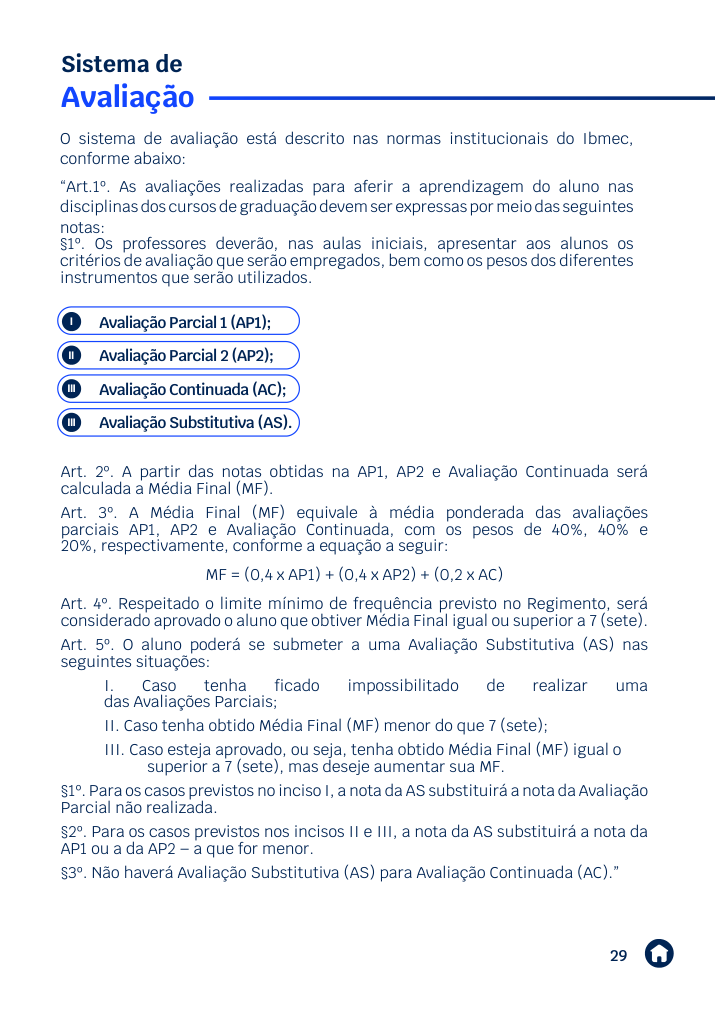

In [14]:
import pymupdf
from IPython.display import display, Image

arquivo_manual = (
    raiz / "data" / "raw" / "pdf" / "GradManualAlunoIbmec.pdf"
)

with pymupdf.open(arquivo_manual) as documento:
    imagem = documento[28].get_pixmap(
        matrix=pymupdf.Matrix(1.2, 1.2)
    )

display(Image(data=imagem.tobytes("png")))

In [15]:
paginas_com_divergencia = {
    ("GradManualAlunoIbmec.pdf", "29"),
    ("GuiadoAlunoIbmecFariaLima.pdf", "4"),
}

motivo_divergencia = (
    "Divergência documental sobre elegibilidade para AS com média 7: "
    "manual informa igual ou superior a 7; guia informa maior que 7. "
    "Vigência e precedência ainda não confirmadas."
)

corpus_apos_avaliacao = []
exclusoes_avaliacao = []

for registro in corpus_em_revisao:
    identificacao = (
        registro["arquivo"],
        str(registro.get("pagina", "")),
    )

    if identificacao in paginas_com_divergencia:
        exclusoes_avaliacao.append({
            "arquivo": registro["arquivo"],
            "pagina": registro["pagina"],
            "mes": registro.get("mes", ""),
            "motivo": motivo_divergencia,
        })
    else:
        corpus_apos_avaliacao.append(registro.copy())

exclusoes_apos_avaliacao = (
    exclusoes_em_revisao + exclusoes_avaliacao
)

assert len(exclusoes_avaliacao) == 2

print("Páginas separadas por divergência:", len(exclusoes_avaliacao))
print("Registros mantidos:", len(corpus_apos_avaliacao))
print("Exclusões acumuladas:", len(exclusoes_apos_avaliacao))

Páginas separadas por divergência: 2
Registros mantidos: 106
Exclusões acumuladas: 24


In [16]:
from collections import defaultdict, Counter
from itertools import combinations
import re

indice_sequencias = defaultdict(set)

for indice, registro in enumerate(corpus_apos_avaliacao):
    palavras = re.findall(r"\w+", registro["texto"].casefold())

    for inicio in range(len(palavras) - 11):
        sequencia = tuple(palavras[inicio:inicio + 12])
        indice_sequencias[sequencia].add(indice)

pares_sobrepostos = Counter()

for indices in indice_sequencias.values():
    for primeiro, segundo in combinations(sorted(indices), 2):
        fonte_a = corpus_apos_avaliacao[primeiro]["arquivo"]
        fonte_b = corpus_apos_avaliacao[segundo]["arquivo"]

        if fonte_a != fonte_b:
            pares_sobrepostos[(primeiro, segundo)] += 1

sobreposicoes = []

for (primeiro, segundo), quantidade in pares_sobrepostos.most_common():
    if quantidade < 5:
        continue

    a = corpus_apos_avaliacao[primeiro]
    b = corpus_apos_avaliacao[segundo]

    sobreposicoes.append({
        "arquivo_a": a["arquivo"],
        "pagina_a": a.get("pagina", ""),
        "arquivo_b": b["arquivo"],
        "pagina_b": b.get("pagina", ""),
        "sequencias_compartilhadas": quantidade,
    })

print("Pares sinalizados:", len(sobreposicoes))

for par in sobreposicoes:
    print(
        f"{par['arquivo_a']} p.{par['pagina_a']} ↔ "
        f"{par['arquivo_b']} p.{par['pagina_b']} | "
        f"{par['sequencias_compartilhadas']} sequências"
    )

Pares sinalizados: 7
GradManualAlunoIbmec.pdf p.14 ↔ GuiaCalouroIbmecFL.pdf p.16 | 112 sequências
GuiaCalouroIbmecFL.pdf p.28 ↔ 18.html p. | 41 sequências
GradManualAlunoIbmec.pdf p.46 ↔ GuiaCalouroIbmecFL.pdf p.24 | 36 sequências
GradManualAlunoIbmec.pdf p.28 ↔ 08.html p. | 32 sequências
GradManualAlunoIbmec.pdf p.27 ↔ 05.html p. | 30 sequências
GradManualAlunoIbmec.pdf p.26 ↔ GuiaCalouroIbmecFL.pdf p.6 | 8 sequências
GradManualAlunoIbmec.pdf p.43 ↔ GuiaCalouroIbmecFL.pdf p.27 | 6 sequências


In [17]:
corpus_apos_sobreposicoes = []
exclusoes_sobreposicoes = []

for registro in corpus_apos_avaliacao:
    if registro["arquivo"] == "18.html":
        exclusoes_sobreposicoes.append({
            "arquivo": registro["arquivo"],
            "pagina": registro.get("pagina", ""),
            "mes": registro.get("mes", ""),
            "motivo": (
                "Conteúdo geral de AAC redundante com a página 28 "
                "do GuiaCalouroIbmecFL.pdf, que acrescenta orientações."
            ),
        })
    else:
        corpus_apos_sobreposicoes.append(registro.copy())

exclusoes_apos_sobreposicoes = (
    exclusoes_apos_avaliacao + exclusoes_sobreposicoes
)

# Registra também o tratamento dos pares encontrados.
for par in sobreposicoes:
    par["tratamento"] = (
        "Retirar 18.html; manter Guia do Calouro p.28."
        if "18.html" in {par["arquivo_a"], par["arquivo_b"]}
        else "Manter ambas: há informações complementares."
    )

assert len(exclusoes_sobreposicoes) == 1

print("Registros mantidos:", len(corpus_apos_sobreposicoes))
print("Exclusões acumuladas:", len(exclusoes_apos_sobreposicoes))

Registros mantidos: 105
Exclusões acumuladas: 25


In [18]:
abrangencias_documentadas = {
    "GradManualAlunoIbmec.pdf": "Graduação — orientação geral",
    "GuiadoAlunoIbmecFariaLima.pdf": "Faria Lima",
    "GuiaCalouroIbmecFL.pdf": "Faria Lima",
    "Calendario_Academico_2026_2_Ibmec_SP_v5_08310586a3.pdf": "São Paulo",
    "17.html": "São Paulo",
}

nome_calendario = (
    "Calendario_Academico_2026_2_Ibmec_SP_v5_08310586a3.pdf"
)

corpus_com_metadados = []

for registro in corpus_apos_sobreposicoes:
    copia = registro.copy()

    copia["abrangencia_documentada"] = (
        abrangencias_documentadas.get(
            registro["arquivo"],
            "Sem unidade exclusiva identificada no conteúdo revisado",
        )
    )

    copia["periodo_documentado"] = (
        "2026.2" if registro["arquivo"] == nome_calendario else ""
    )

    corpus_com_metadados.append(copia)

for arquivo in sorted({r["arquivo"] for r in corpus_com_metadados}):
    exemplo = next(
        r for r in corpus_com_metadados if r["arquivo"] == arquivo
    )

    print(
        f"{arquivo}\n"
        f"  Abrangência: {exemplo['abrangencia_documentada']}\n"
        f"  Período: {exemplo['periodo_documentado'] or 'Não identificado'}"
    )

05.html
  Abrangência: Sem unidade exclusiva identificada no conteúdo revisado
  Período: Não identificado
07.html
  Abrangência: Sem unidade exclusiva identificada no conteúdo revisado
  Período: Não identificado
08.html
  Abrangência: Sem unidade exclusiva identificada no conteúdo revisado
  Período: Não identificado
09.html
  Abrangência: Sem unidade exclusiva identificada no conteúdo revisado
  Período: Não identificado
10.html
  Abrangência: Sem unidade exclusiva identificada no conteúdo revisado
  Período: Não identificado
11.html
  Abrangência: Sem unidade exclusiva identificada no conteúdo revisado
  Período: Não identificado
17.html
  Abrangência: São Paulo
  Período: Não identificado
Calendario_Academico_2026_2_Ibmec_SP_v5_08310586a3.pdf
  Abrangência: São Paulo
  Período: 2026.2
GradManualAlunoIbmec.pdf
  Abrangência: Graduação — orientação geral
  Período: Não identificado
GuiaCalouroIbmecFL.pdf
  Abrangência: Faria Lima
  Período: Não identificado
GuiadoAlunoIbmecFariaLima

In [19]:
referencias_pdf = {
    "GradManualAlunoIbmec.pdf": {
        "titulo": "Manual do Aluno da Graduação",
        "url_referencia": "https://www.ibmec.br/blog/aluno/guia-do-estudante",
        "url_documento": "https://d1v1kp8opafsrk.cloudfront.net/ibmec/manuais/manuadoaluno/GradManualAlunoIbmec.pdf",
    },
    "GuiadoAlunoIbmecFariaLima.pdf": {
        "titulo": "Guia do Aluno — Faria Lima",
        "url_referencia": "https://www.ibmec.br/blog/aluno/guia-do-aluno-ibmec",
        "url_documento": "https://d1v1kp8opafsrk.cloudfront.net/ibmec/2026/comunicacoes/GuiadoAlunoIbmecFariaLima.pdf",
    },
    "GuiaCalouroIbmecFL.pdf": {
        "titulo": "Guia do Calouro — Faria Lima",
        "url_referencia": "https://www.ibmec.br/blog/aluno/guia-do-calouro-ibmec",
        "url_documento": "",
    },
    nome_calendario: {
        "titulo": "Calendário Acadêmico São Paulo — 2026.2",
        "url_referencia": "https://www.ibmec.br/blog/graduacao/calendario-academico-graduacao-26.2",
        "url_documento": "https://cdn.dev.portal.estacio.br/Calendario_Academico_2026_2_Ibmec_SP_v5_08310586a3.pdf",
    },
}

corpus_referenciado = []

for registro in corpus_com_metadados:
    copia = registro.copy()

    if registro["tipo"] == "pdf":
        copia.update(referencias_pdf[registro["arquivo"]])
    else:
        copia["url_referencia"] = registro["url"]
        copia["url_documento"] = ""

    corpus_referenciado.append(copia)

assert all(r["titulo"] and r["url_referencia"] for r in corpus_referenciado)

print("Registros com título e referência:", len(corpus_referenciado))
print("PDFs com referência:", len(referencias_pdf))

Registros com título e referência: 105
PDFs com referência: 4


In [20]:
paginas_sumario = {
    ("GradManualAlunoIbmec.pdf", "2"),
    ("GradManualAlunoIbmec.pdf", "3"),
    ("GradManualAlunoIbmec.pdf", "4"),
    ("GuiaCalouroIbmecFL.pdf", "3"),
}

corpus_conteudo = []
exclusoes_sumario = []

for registro in corpus_referenciado:
    identificacao = (
        registro["arquivo"],
        str(registro.get("pagina", "")),
    )

    if identificacao in paginas_sumario:
        exclusoes_sumario.append({
            "arquivo": registro["arquivo"],
            "pagina": registro["pagina"],
            "mes": registro.get("mes", ""),
            "motivo": "Sumário: índice de assuntos, sem orientação completa.",
        })
    else:
        corpus_conteudo.append(registro.copy())

exclusoes_consolidadas = (
    exclusoes_apos_sobreposicoes + exclusoes_sumario
)

assert len(exclusoes_sumario) == 4

print("Sumários retirados:", len(exclusoes_sumario))
print("Registros mantidos:", len(corpus_conteudo))
print("Exclusões acumuladas:", len(exclusoes_consolidadas))

Sumários retirados: 4
Registros mantidos: 101
Exclusões acumuladas: 29


In [21]:
def normalizar_espacos(texto):
    texto = texto.replace("\r\n", "\n").replace("\r", "\n")
    texto = texto.replace("\u00a0", " ")

    linhas = [
        re.sub(r"[^\S\n]+", " ", linha).strip()
        for linha in texto.split("\n")
    ]

    resultado = "\n".join(linhas)
    return re.sub(r"\n{3,}", "\n\n", resultado).strip()


corpus_normalizado = []

for registro in corpus_conteudo:
    copia = registro.copy()
    copia["texto_limpo"] = normalizar_espacos(registro["texto"])

    # Confere que nenhum caractere além de espaços foi alterado.
    assert (
        re.sub(r"\s+", "", copia["texto_limpo"])
        == re.sub(r"\s+", "", registro["texto"])
    )

    assert copia["texto_limpo"], "A limpeza produziu texto vazio."
    corpus_normalizado.append(copia)

alterados = sum(
    r["texto"] != r["texto_limpo"]
    for r in corpus_normalizado
)

print("Registros normalizados:", len(corpus_normalizado))
print("Registros com ajuste de espaços:", alterados)
print("Conferência: caracteres não brancos preservados.")

Registros normalizados: 101
Registros com ajuste de espaços: 95
Conferência: caracteres não brancos preservados.


In [22]:
from IPython.display import display, HTML
from html import escape

amostras = [
    ("GradManualAlunoIbmec.pdf", "38", ""),
    (nome_calendario, "1", "setembro"),
    ("07.html", "", ""),
]

for arquivo, pagina, mes in amostras:
    registro = next(
        r for r in corpus_normalizado
        if r["arquivo"] == arquivo
        and r.get("pagina", "") == pagina
        and r.get("mes", "") == mes
    )

    print(f"\n{arquivo} | página {pagina or '—'} | {mes}")

    display(HTML(
        '<pre style="white-space: pre-wrap; '
        'max-height: 350px; overflow-y: auto;">'
        + escape(registro["texto_limpo"])
        + '</pre>'
    ))


GradManualAlunoIbmec.pdf | página 38 | 



Calendario_Academico_2026_2_Ibmec_SP_v5_08310586a3.pdf | página 1 | setembro



07.html | página — | 


In [23]:
fontes_v2 = {r["arquivo"] for r in corpus_normalizado}

revisao_v2 = []

for registro in carregar_csv("revisao_fontes_v1.csv"):
    copia = registro.copy()
    copia["decisao"] = (
        "selecionada_com_restricoes"
        if registro["arquivo"] in fontes_v2
        else "fora_da_versao_v2"
    )

    motivos = sorted({
        r["motivo"]
        for r in exclusoes_consolidadas
        if r["arquivo"] == registro["arquivo"]
    })

    copia["observacao"] = " | ".join(
        parte
        for parte in [registro["observacao"]] + motivos
        if parte
    )
    revisao_v2.append(copia)

corpus_v2 = []

for registro in corpus_normalizado:
    copia = registro.copy()
    copia["status_revisao"] = "curadoria_v2_com_restricoes"
    corpus_v2.append(copia)

saidas_v2 = {
    "corpus_v2.csv": corpus_v2,
    "exclusoes_corpus_v2.csv": exclusoes_consolidadas,
    "sobreposicoes_v2.csv": sobreposicoes,
    "revisao_fontes_v2.csv": revisao_v2,
}

for nome in saidas_v2:
    if (pasta_processados / nome).exists():
        raise FileExistsError(f"{nome} já existe; nada foi sobrescrito.")

for nome, linhas in saidas_v2.items():
    colunas = list(dict.fromkeys(
        chave for linha in linhas for chave in linha
    ))

    linhas_padronizadas = [
        {coluna: str(linha.get(coluna, "")) for coluna in colunas}
        for linha in linhas
    ]

    caminho = pasta_processados / nome

    with caminho.open("x", encoding="utf-8-sig", newline="") as arquivo:
        escritor = csv.DictWriter(
            arquivo, fieldnames=colunas, delimiter=";"
        )
        escritor.writeheader()
        escritor.writerows(linhas_padronizadas)

    recuperadas = carregar_csv(nome)
    assert recuperadas == linhas_padronizadas, f"Erro em {nome}"

    print(f"{nome}: {len(recuperadas)} registros — conferido")

corpus_v2.csv: 101 registros — conferido
exclusoes_corpus_v2.csv: 29 registros — conferido
sobreposicoes_v2.csv: 7 registros — conferido
revisao_fontes_v2.csv: 18 registros — conferido


In [24]:
corpus_final = carregar_csv("corpus_v2.csv")
exclusoes_finais = carregar_csv("exclusoes_corpus_v2.csv")
revisao_final = carregar_csv("revisao_fontes_v2.csv")

originais = (
    carregar_csv("textos_pdfs.csv")
    + carregar_csv("textos_html.csv")
)

def identificar(registro):
    return (
        registro["arquivo"],
        registro.get("pagina", ""),
        registro.get("mes", ""),
    )

originais_por_id = {identificar(r): r for r in originais}
ids_mantidos = {identificar(r) for r in corpus_final}
ids_excluidos = {identificar(r) for r in exclusoes_finais}

assert len(originais_por_id) == len(originais) == 130
assert len(ids_mantidos) == len(corpus_final) == 101
assert len(ids_excluidos) == len(exclusoes_finais) == 29
assert ids_mantidos.isdisjoint(ids_excluidos)
assert ids_mantidos | ids_excluidos == set(originais_por_id)

for registro in corpus_final:
    original = originais_por_id[identificar(registro)]

    assert registro["texto"] == original["texto"]
    assert registro["texto_limpo"] == normalizar_espacos(original["texto"])
    assert registro["texto_limpo"].strip()
    assert registro["titulo"] and registro["url_referencia"]
    assert registro["status_revisao"] == "curadoria_v2_com_restricoes"

fontes_mantidas = {r["arquivo"] for r in corpus_final}
fontes_na_revisao = {
    r["arquivo"]
    for r in revisao_final
    if r["decisao"] == "selecionada_com_restricoes"
}

assert len(revisao_final) == 18
assert fontes_mantidas == fontes_na_revisao
assert len(fontes_mantidas) == 11

print("CONFERÊNCIA FINAL CONCLUÍDA")
print("101 registros de 11 fontes mantidos.")
print("29 exclusões justificadas; 130 originais contabilizados.")
print("Textos originais preservados e normalização conferida.")
print("Referências preenchidas e seleção consistente com a revisão.")

CONFERÊNCIA FINAL CONCLUÍDA
101 registros de 11 fontes mantidos.
29 exclusões justificadas; 130 originais contabilizados.
Textos originais preservados e normalização conferida.
Referências preenchidas e seleção consistente com a revisão.


In [25]:
corpus_base = carregar_csv("corpus_v2.csv")
exclusoes_base = carregar_csv("exclusoes_corpus_v2.csv")

paginas_contatos_pendentes = {
    "GradManualAlunoIbmec.pdf": {"12"},
    "GuiadoAlunoIbmecFariaLima.pdf": {"9", "11"},
    "GuiaCalouroIbmecFL.pdf": {
        "5", "11", "12", "13", "14", "15", "19"
    },
}

html_contatos_pendentes = {"10.html", "11.html"}

corpus_sem_contatos_pendentes = []
exclusoes_contatos = []

for registro in corpus_base:
    arquivo = registro["arquivo"]
    pagina = registro.get("pagina", "")

    excluir = (
        pagina in paginas_contatos_pendentes.get(arquivo, set())
        or arquivo in html_contatos_pendentes
    )

    if excluir:
        exclusoes_contatos.append({
            "arquivo": arquivo,
            "pagina": pagina,
            "mes": registro.get("mes", ""),
            "motivo": (
                "Registro contém contatos, cargos ou horários cuja "
                "atualidade não foi confirmada. Exclusão integral "
                "conservadora; original preservado."
            ),
        })
    else:
        corpus_sem_contatos_pendentes.append(registro.copy())

exclusoes_consolidadas_v3 = exclusoes_base + exclusoes_contatos

assert len(exclusoes_contatos) == 12

print("Registros separados:", len(exclusoes_contatos))
print("Registros mantidos:", len(corpus_sem_contatos_pendentes))
print("Exclusões acumuladas:", len(exclusoes_consolidadas_v3))

Registros separados: 12
Registros mantidos: 89
Exclusões acumuladas: 41


In [26]:
atualizacao_paginas_pdf = {
    "GuiadoAlunoIbmecFariaLima.pdf": "2026-01-19",
    "GuiaCalouroIbmecFL.pdf": "2026-03-18",
    "GradManualAlunoIbmec.pdf": "2026-07-16",
    nome_calendario: "2026-08-04",
}

corpus_v3 = []

for registro in corpus_sem_contatos_pendentes:
    copia = registro.copy()
    arquivo = registro["arquivo"]

    copia["status_revisao"] = "selecionado_curadoria_v3"
    copia["data_revisao"] = "2026-10-20"
    copia["limites_uso"] = (
        "Base documental para protótipo acadêmico. "
        "Respeitar abrangência e período; não pressupor vigência atual."
    )

    copia["pagina_fonte_atualizada_em"] = (
        atualizacao_paginas_pdf.get(arquivo, "")
    )
    copia["referencia_pdf_conferida_em"] = (
        "2026-10-20" if arquivo in atualizacao_paginas_pdf else ""
    )
    copia["situacao_edicao"] = (
        "Referência oficial localizada; edição interna não identificada. "
        "Cópia local não comparada com novo download."
        if registro["tipo"] == "pdf"
        else "HTML preservado da coleta original."
    )

    if arquivo == "GuiaCalouroIbmecFL.pdf":
        copia["url_documento"] = (
            "https://d1v1kp8opafsrk.cloudfront.net/"
            "ibmec/manuais/guiadocalouro/GuiaCalouroIbmecFL.pdf"
        )

    corpus_v3.append(copia)

assert len(corpus_v3) == 89
assert all(r["texto_limpo"].strip() for r in corpus_v3)
assert all(r["titulo"] and r["url_referencia"] for r in corpus_v3)

print("Registros preparados:", len(corpus_v3))
print("Fontes mantidas:", len({r["arquivo"] for r in corpus_v3}))

Registros preparados: 89
Fontes mantidas: 9


In [27]:
def chave_v3(registro):
    return (
        registro["arquivo"],
        registro.get("pagina", ""),
        registro.get("mes", ""),
    )


originais = (
    carregar_csv("textos_pdfs.csv")
    + carregar_csv("textos_html.csv")
)
originais_por_id = {chave_v3(r): r for r in originais}

ids_mantidos = {chave_v3(r) for r in corpus_v3}
ids_excluidos = {
    chave_v3(r) for r in exclusoes_consolidadas_v3
}

assert len(originais_por_id) == len(originais) == 130
assert len(ids_mantidos) == len(corpus_v3) == 89
assert len(ids_excluidos) == len(exclusoes_consolidadas_v3) == 41
assert ids_mantidos.isdisjoint(ids_excluidos)
assert ids_mantidos | ids_excluidos == set(originais_por_id)

for registro in corpus_v3:
    original = originais_por_id[chave_v3(registro)]
    assert registro["texto"] == original["texto"]
    assert registro["texto_limpo"] == normalizar_espacos(original["texto"])

fontes_v3 = {r["arquivo"] for r in corpus_v3}
assert len(fontes_v3) == 9

revisao_v3 = []

for anterior in carregar_csv("revisao_fontes_v2.csv"):
    arquivo = anterior["arquivo"]

    motivos = sorted({
        r["motivo"]
        for r in exclusoes_consolidadas_v3
        if r["arquivo"] == arquivo
    })

    revisao_v3.append({
        "arquivo": arquivo,
        "decisao": (
            "incluida_com_restricoes"
            if arquivo in fontes_v3 else "excluida_da_versao_v3"
        ),
        "registros_mantidos": sum(
            r["arquivo"] == arquivo for r in corpus_v3
        ),
        "registros_excluidos": sum(
            r["arquivo"] == arquivo
            for r in exclusoes_consolidadas_v3
        ),
        "motivos_exclusoes": " | ".join(motivos),
        "historico_revisao": anterior["observacao"],
        "data_revisao": "2026-10-20",
    })

assert len(revisao_v3) == 18

saidas_v3 = {
    "corpus_v3.csv": corpus_v3,
    "exclusoes_corpus_v3.csv": exclusoes_consolidadas_v3,
    "revisao_fontes_v3.csv": revisao_v3,
    "sobreposicoes_v3.csv": carregar_csv("sobreposicoes_v2.csv"),
}

for nome in saidas_v3:
    if (pasta_processados / nome).exists():
        raise FileExistsError(f"{nome} já existe; nada foi sobrescrito.")

for nome, linhas in saidas_v3.items():
    colunas = list(dict.fromkeys(
        campo for linha in linhas for campo in linha
    ))

    esperadas = [
        {campo: str(linha.get(campo, "")) for campo in colunas}
        for linha in linhas
    ]

    with (pasta_processados / nome).open(
        "x", encoding="utf-8-sig", newline=""
    ) as arquivo:
        escritor = csv.DictWriter(
            arquivo, fieldnames=colunas, delimiter=";"
        )
        escritor.writeheader()
        escritor.writerows(esperadas)

    assert carregar_csv(nome) == esperadas
    print(f"{nome}: {len(esperadas)} registros — conferido")

print("\nCURADORIA V3 CONCLUÍDA")
print("89 registros de 9 fontes; 41 exclusões documentadas.")
print("Todos os 130 registros originais contabilizados.")

corpus_v3.csv: 89 registros — conferido
exclusoes_corpus_v3.csv: 41 registros — conferido
revisao_fontes_v3.csv: 18 registros — conferido
sobreposicoes_v3.csv: 7 registros — conferido

CURADORIA V3 CONCLUÍDA
89 registros de 9 fontes; 41 exclusões documentadas.
Todos os 130 registros originais contabilizados.
